# Семинар 1. Что такое NLP, применение, обзор инструментов

---
# ТЕОРИЯ

## 0. О курсе

**Цель курса:** научиться извлекать из больших массивов текстов (СМИ, соцсети, отзывы, Telegram) знания, полезные для рекламы и PR: собирать тексты, анализировать их средствами Python и представлять результат заказчику.

| Блок | Семинары | Темы |
|---|---|---|
| Основы | 1–2 | Введение, Python для работы с текстом |
| Сбор данных | 3–4 | Парсинг HTML, Telegram API |
| Данные и предобработка | 5–6 | pandas, токенизация, нормализация, стоп-слова, лемматизация |
| Описательный анализ | 7–8 | Статистика текстов, визуализация |
| Машинное обучение | 9–13 | Регрессия, векторные представления, классификация, кластеризация, тональность |
| Приложение | 14 | Публикация NLP-приложения: Streamlit |
| Продвинутые методы | 15–16 | Тематическое моделирование, предобученные модели |
| Проект | 17–18 | Защита проектов |

**Контроль:** лабораторные работы (семинары 3, 6, 10, 13), три ДЗ (выдаются на семинарах 4, 7, 11, срок — 2 недели), проект (ТЗ после 9-го семинара, защита на 17–18-м), посещаемость.

<!-- ПРЕПОДАВАТЕЛЮ: вставьте формулу оценки из РПД -->
**Формула оценки:** 0,35 · Проект + 0,25 · ДЗ + 0,20 · ЛР + 0,20 · Активность

## 1. Что такое text mining и NLP

### Определения
**Text mining (интеллектуальный анализ текстов)** — извлечение знаний, закономерностей и трендов из больших массивов текстов. Это аналитическая дисциплина: её интересует не сам язык, а то, **что тексты говорят о мире**: о клиентах, бренде, рынке, общественном мнении.

**NLP (Natural Language Processing, автоматическая обработка естественного языка)** — область на стыке лингвистики и информатики, которая разрабатывает методы, позволяющие компьютеру анализировать, понимать и порождать тексты.

Упрощённо: **NLP — это набор инструментов, text mining — это работа, которую аналитик делает этими инструментами.** Лемматизатор, модель тональности и тематическая модель — продукты NLP. Вывод «за три месяца доля жалоб на приложение выросла вчетверо» — результат text mining.

### Как text mining соотносится с соседними областями
| Область | Что изучает | Отличие от text mining |
|---|---|---|
| **Data mining** | Закономерности в структурированных данных: таблицах, транзакциях | Text mining — то же самое, но для неструктурированных текстов, которые сначала нужно превратить в данные |
| **NLP** | Методы обработки языка | Интересуется самим языком и технологиями; text mining использует NLP как средство |
| **Корпусная лингвистика** | Язык на материале больших собраний текстов | Цель — знание о языке; цель text mining — знание о предмете текстов |
| **Контент-анализ** (социология, медиаисследования) | Количественный анализ содержания СМИ | Классический предшественник text mining; раньше тексты кодировались вручную |
| **Digital humanities** | Цифровые методы в гуманитарных науках | Применяет text mining к литературе, истории, архивам |

### Близкое и дальнее чтение
Литературовед Франко Моретти противопоставил два способа работы с текстами:
- **Близкое чтение (close reading)** — внимательное прочтение отдельных текстов. Глубоко, но можно прочитать лишь десятки или сотни текстов.
- **Дальнее чтение (distant reading)** — анализ тысяч и миллионов текстов вычислительными методами. Видны закономерности, которые не заметит ни один читатель: тренды, частоты, связи. Но теряются нюансы отдельного текста.

Для PR это особенно наглядно: прочитать 50 отзывов может любой стажёр, но 50 000 упоминаний бренда за год — нет. При этом **хорошее исследование всегда сочетает оба способа**: дальнее чтение находит закономерность, близкое объясняет её и проверяет. Именно это мы сделаем в практической части.

### Что text mining может и чего не может
| ✅ Может | ❌ Не может |
|---|---|
| Быстро обработать тысячи текстов | Заменить понимание контекста и знание отрасли |
| Показать, что и как часто упоминается | Сам объяснить, **почему** так происходит |
| Найти тренды, всплески, аномалии | Гарантировать отсутствие ошибок |
| Сравнить бренды, периоды, аудитории | Сказать что-то о тех, кто не пишет отзывов |
| Сделать анализ воспроизводимым | Сформулировать за вас исследовательский вопрос |

### Ключевые термины курса
| Термин | Значение | Пример |
|---|---|---|
| **Корпус** | Собрание текстов, подготовленное для анализа | Все отзывы о двух кофейнях за 2025 год |
| **Документ** | Одна единица корпуса | Один отзыв, пост, статья |
| **Метаданные** | Информация *о* тексте | Дата, источник, автор, оценка |
| **Токен** | Минимальная единица анализа | «Кофе», «390», «!!!», «🔥» |
| **Лемма** | Словарная форма слова | *кофейней* → *кофейня* |
| **Частота** | Сколько раз слово встречается в корпусе | «кофе» встречается в отзывах сотни раз |
| **Контекст** | Окружение слова в тексте | «Новое [приложение] постоянно вылетает» |

## 2. Почему текст трудно анализировать

Текст — **неструктурированные данные**. В таблице продаж каждое значение лежит в своём столбце. В отзыве «Кофе норм, но ждали полчаса, а за 390 р. можно и побыстрее» оценка, тема и цена спрятаны внутри фразы, и их нужно оттуда извлечь.

| Трудность | Пример | Что ломается |
|---|---|---|
| **Словоизменение** | *кофейня, кофейни, кофейней, кофейнях* | Одно слово считается как несколько разных |
| **Неоднозначность** | *стали* — «стать» или «сталь»? | Неверная лемма, неверный подсчёт |
| **Синонимия и варианты названий** | *Сбер / Сбербанк / SberBank / зелёный банк* | Часть упоминаний бренда теряется |
| **Отрицание** | *не плохо*, *вряд ли вернусь* | Подсчёт «хороших» и «плохих» слов ошибается |
| **Ирония** | *Отличный сервис: ждали всего полчаса 👍* | Позитивные слова, негативный смысл |
| **Неформальный язык** | *кофэ, имба, ооочень, спс* | Словари и модели не знают этих форм |
| **Новые слова** | Названия новых продуктов, мемы | Модель, обученная раньше, их не знает |

Ошибки на каждом этапе обработки переходят в итоговые цифры. Поэтому аналитик всегда проверяет результаты глазами: это займёт заметное место и в нашей практике.

## 3. Как устроено исследование на текстовых данных

Text mining — это прежде всего **исследование**, а не запуск программы. Типичный процесс:

```
 1. ВОПРОС → 2. КОРПУС → 3. ПОДГОТОВКА → 4. ПРЕДСТАВЛЕНИЕ → 5. АНАЛИЗ → 6. ИНТЕРПРЕТАЦИЯ → 7. ПРОВЕРКА
                                                                              ↑                  │
                                                                              └──────────────────┘
```

| Этап | Что делаем | Пример: сеть кофеен | Семинары |
|---|---|---|---|
| **1. Вопрос** | Переводим запрос заказчика в исследовательский вопрос | «Почему падает рейтинг?» → «Какие темы преобладают в негативных отзывах и как они менялись в течение года?» | — |
| **2. Корпус** | Решаем, какие тексты нужны, откуда и за какой период; собираем | Отзывы с Яндекс Карт и 2ГИС за 2025 год | 3–4 |
| **3. Подготовка** | Очищаем, токенизируем, лемматизируем, убираем стоп-слова | «Ждали заказ 25 минут!» → *ждать, заказ, минута* | 5–6 |
| **4. Представление** | Превращаем тексты в числа | Таблица частот слов, векторы | 10 |
| **5. Анализ** | Считаем, сравниваем, моделируем | Частоты, сравнение периодов, тональность, темы | 7–8, 11–16 |
| **6. Интерпретация** | Объясняем, что значат цифры | «Рост жалоб совпал с запуском нового приложения» | все |
| **7. Проверка** | Читаем примеры, ищем ошибки и альтернативные объяснения | Читаем 30 отзывов со словом «приложение» | все |

Три правила хорошего исследования:
1. **Начинайте с вопроса, а не с метода.** «Давайте сделаем тематическую модель» — не вопрос.
2. **Корпус определяет выводы.** Отзывы на картах пишут в основном очень довольные и очень недовольные клиенты. Выводы касаются тех, кто пишет, а не всех клиентов.
3. **Цифра без примера ничего не доказывает.** Каждую закономерность подтверждайте конкретными текстами.

## 4. Задачи text mining и как менялись методы

### Три типа задач
| Тип | Вопрос | Задачи и методы | Пример в PR | Семинары |
|---|---|---|---|---|
| **Описательные** | Что в текстах есть? | Частоты слов, n-граммы, ключевые слова, сравнение корпусов, динамика | О чём чаще всего пишут клиенты? Чем отзывы о нас отличаются от отзывов о конкуренте? | 7–8 |
| **Разведочные** | Какая в текстах скрыта структура? | Кластеризация, тематическое моделирование | Какие группы проблем вообще встречаются в обращениях? | 11, 15 |
| **Предсказательные** | К какой категории относится текст? Какое число ему соответствует? | Классификация, анализ тональности, регрессия, извлечение сущностей | Негативный ли отзыв? Какую оценку поставит клиент? Упоминается ли конкурент? | 9–13, 16 |

### Основные задачи подробнее
| Задача | Вход → выход | Пример |
|---|---|---|
| **Частотный анализ** | Корпус → список слов с частотами | Топ-20 слов в негативных отзывах |
| **Ключевые слова (keyness)** | Два корпуса → слова, характерные для каждого | Слова, отличающие отзывы о нас от отзывов о конкуренте |
| **Конкорданс** | Слово → все его контексты | Как именно пишут о «цене»? |
| **Сочетаемость (коллокации)** | Слово → его частые «соседи» | С чем связывают «приложение»? |
| **Классификация** | Текст → категория | Жалоба / вопрос / благодарность |
| **Анализ тональности** | Текст → позитив / негатив / нейтрально | Доля негатива в упоминаниях за неделю |
| **Кластеризация** | Корпус → группы похожих текстов | Какие типы отзывов существуют |
| **Тематическое моделирование** | Корпус → темы и их ключевые слова | О чём пишут в отраслевых Telegram-каналах |
| **Извлечение сущностей (NER)** | Текст → организации, персоны, места | Все упоминания бренда, спикеров и конкурентов |
| **Суммаризация и генерация** | Текст или запрос → новый текст | Дайджест публикаций, варианты заголовков |

### Как менялись методы
| Период | Подход | Идея | Где пригодится в курсе |
|---|---|---|---|
| 1950–1980-е | **Правила и словари** | Лингвисты описывают язык вручную | Словари тональности, стоп-слова, поиск по шаблонам |
| 1990–2000-е | **Статистика корпусов** | Считаем частоты и совместную встречаемость слов в больших корпусах | Частотный анализ, ключевые слова, TF-IDF |
| 2000–2010-е | **Машинное обучение** | Модель учится на размеченных примерах | Классификация, тональность, кластеризация |
| 2013–2017 | **Векторы слов** (Word2Vec) | Слова — наборы чисел; близкие по смыслу слова — близкие векторы | Векторные представления |
| с 2017–2018 | **Трансформеры и LLM** (BERT, GPT, GigaChat, YandexGPT) | Модели, предобученные на огромных корпусах, понимают контекст | Предобученные модели, генерация идей |

Старые методы не устарели. Частотный анализ прозрачен и быстр, классическое машинное обучение хорошо объяснимо, нейросети точнее, но тяжелее и менее прозрачны. **Аналитик выбирает метод под вопрос.**

## 5. Применение в рекламе и PR

| Направление | Вопрос заказчика | Тексты | Задачи text mining | Результат |
|---|---|---|---|---|
| **Медиамониторинг, social listening** | Что, где и сколько о нас пишут? | СМИ, соцсети, Telegram | Поиск упоминаний, NER, удаление дубликатов | Динамика упоминаний по источникам |
| **Управление репутацией** | Хорошо или плохо о нас говорят? Не начинается ли кризис? | Упоминания бренда | Тональность, поиск всплесков | Индекс тональности, сигналы о кризисе |
| **Голос клиента** | За что хвалят и за что ругают? | Отзывы, обращения, опросы | Классификация, аспектная тональность, темы | Рейтинг проблем по частоте |
| **Анализ аудитории** | Какими словами говорят клиенты, что для них важно? | Сообщества, комментарии | Частоты, ключевые слова, темы | Словарь аудитории, мотивы и «боли» |
| **Конкурентный анализ** | Чем наш образ отличается от образа конкурента? | Упоминания нас и конкурентов | Сравнение корпусов, тональность | Карта позиционирования |
| **Оценка кампаний** | Сработала ли кампания? | Упоминания до и после | Сравнение периодов | Изменение тем и тональности |
| **Контент** | Какие тексты работают лучше? | Собственные посты бренда | Связь характеристик текста с откликом, генерация | Рекомендации, варианты текстов |

**Готовые платформы** (Медиалогия, Brand Analytics, СКАН-Интерфакс и др.) решают типовые задачи мониторинга. Умение делать анализ самому нужно, чтобы:
- отвечать на нестандартные вопросы заказчика;
- работать с данными, которых нет в платформах (внутренние обращения, опросы, нишевые площадки);
- критически оценивать чужие цифры: откуда «73% позитива» и сколько в этой оценке ошибок.

## 6. Обзор методов и инструментов

Весь курс проходит на **Python** в **Google Colab**: это стандарт индустрии анализа данных, со множеством готовых **библиотек** — наборов инструментов, которые устанавливаются командой `pip install` и подключаются командой `import`.

| Этап | Методы | Основные библиотеки | Альтернативы | Семинары |
|---|---|---|---|---|
| **Сбор данных** | Парсинг HTML, работа с API | `requests`, `BeautifulSoup`, `Selenium`; для Telegram — `Telethon` | `Scrapy`, `Playwright`, `lxml` | 3–4 |
| **Таблицы** | Отбор, группировка, агрегация, даты | `pandas` | `polars`, SQL | 5 |
| **Предобработка** | Токенизация, нормализация, стоп-слова, стемминг, лемматизация | `razdel`, `pymorphy3`, `NLTK` | `spaCy`, `Natasha`, Mystem, `Stanza` | 6 |
| **Описательный анализ** | Частоты, n-граммы, ключевые слова, динамика | `collections.Counter`, `pandas` | `NLTK` | 7 |
| **Визуализация** | Графики, дашборды | `matplotlib`, `seaborn`, `plotly` | `wordcloud` | 8 |
| **Машинное обучение** | Регрессия, классификация, кластеризация, метрики качества | `scikit-learn` | `CatBoost` | 9, 11 |
| **Векторизация** | Мешок слов, TF-IDF, Word2Vec | `scikit-learn`, `gensim` | RusVectōrēs, `navec` | 10 |
| **Тональность** | Словари, ML, нейросети | `scikit-learn`, `transformers` | Словарь RuSentiLex, модели RuBERT | 12–13 |
| **Приложение** | Веб-интерфейс для анализа | `Streamlit` | `Gradio`, `Dash` | 14 |
| **Тематическое моделирование** | LDA, BERTopic | `gensim`, `bertopic` | `scikit-learn`, BigARTM | 15 |
| **Предобученные модели и LLM** | Готовые модели, дообучение, инструкции к LLM | Hugging Face, `transformers` | API GigaChat, YandexGPT | 16 |

### Особенности инструментов для русского языка
- **Лемматизация обязательна.** Из-за богатой морфологии без неё частоты «размазываются» по формам. Инструменты для английского часто ограничиваются стеммингом, для русского этого мало.
- **pymorphy3** работает по словарю OpenCorpora и не видит контекст. **Mystem** (Яндекс) и **spaCy / Natasha** учитывают контекст, но работают медленнее.
- **Natasha** — экосистема инструментов, созданных специально для русского языка: токенизация (`razdel`), морфология, синтаксис, извлечение сущностей.
- **Модели для русского языка:** RuBERT (DeepPavlov, МФТИ), rubert-tiny, модели Сбера; каталог — на **Hugging Face**.


---
## Итоги

1. **Text mining** — извлечение знаний из больших массивов текстов; **NLP** даёт для этого методы.
2. Хорошее исследование начинается с **вопроса**, а не с метода, и сочетает **дальнее чтение** (закономерности на всём корпусе) с **близким** (проверка и объяснение на конкретных текстах).
3. Задачи text mining бывают **описательные, разведочные и предсказательные**.
4. Каждый этап обработки может внести ошибку, поэтому цифры всегда нужно проверять примерами.
5. Сегодня вы пользовались готовыми приборами. За курс вы научитесь создавать их сами: собирать данные (сем. 3–4), обрабатывать тексты (сем. 5–6), считать и визуализировать (сем. 7–8), обучать модели (сем. 9–16).


In [ ]:
!pip install -q pymorphy3 razdel

## Шаг 1. Подключаем библиотеки

| Библиотека | Зачем нужна |
|---|---|
| `pandas` | Работа с таблицами |
| `matplotlib` | Графики |
| `Counter` | Подсчёт: сколько раз встречается каждое слово |
| `razdel` | Деление текста на слова (токенизация) |
| `pymorphy3` | Приведение слов к начальной форме (лемматизация) |

In [ ]:
import pandas as pd                  # таблицы
import matplotlib.pyplot as plt      # графики
from collections import Counter      # подсчёт частот
from razdel import tokenize          # деление текста на слова
import pymorphy3                     # приведение слов к начальной форме

morph = pymorphy3.MorphAnalyzer()

## Шаг 2. Наш корпус

Вы — аналитик агентства, клиенты которого — две конкурирующие кофейни: **«Зерно»** и **«Кофеин»**. Перед вами 80 отзывов за 2025 год.

Каждый отзыв записан как набор из четырёх значений: **дата, кофейня, оценка (1–5 звёзд), текст**. Из списка отзывов сделаем таблицу (`DataFrame`): каждая строка — отзыв, каждый столбец — одна из характеристик.

In [ ]:
reviews = [
    # ---------- «Зерно» ----------
    ("2025-01-09", "Зерно", 5, "Лучший капучино в районе! Бариста приветливые, атмосфера уютная."),
    ("2025-01-17", "Зерно", 4, "Кофе отличный, но цены кусаются: латте за 390 рублей."),
    ("2025-01-26", "Зерно", 5, "Очень уютно, приятная музыка, удобно работать с ноутбуком."),
    ("2025-02-03", "Зерно", 3, "Вкусный раф, но слишком дорого для обычного кофе."),
    ("2025-02-14", "Зерно", 5, "Бариста запомнил мой заказ — приятно! Кофе всегда вкусный."),
    ("2025-02-22", "Зерно", 4, "Атмосфера уютная, кофе ароматный. Дороговато, конечно."),
    ("2025-03-05", "Зерно", 2, "Опять подняли цены. За такие деньги ожидаешь большего."),
    ("2025-03-15", "Зерно", 5, "Отличный эспрессо, зерно свежей обжарки. Рекомендую!"),
    ("2025-03-28", "Зерно", 4, "Вкусный кофе и вежливый персонал, но цены высокие."),
    ("2025-04-06", "Зерно", 5, "Любимая кофейня: вкусный кофе, светло и тихо."),
    ("2025-04-12", "Зерно", 3, "Кофе хороший, но в выходные очередь до двери."),
    ("2025-04-25", "Зерно", 5, "Альтернатива на воронке — огонь 🔥 Бариста всё подробно рассказал."),
    ("2025-05-04", "Зерно", 2, "Слишком дорого. Капучино за 350 рублей — это перебор."),
    ("2025-05-18", "Зерно", 5, "Уютное место, приятная музыка, вкусный флэт уайт."),
    ("2025-05-30", "Зерно", 4, "Кофе отличный. Жаль, что цены растут."),
    ("2025-06-07", "Зерно", 5, "Приветливые бариста и очень вкусный кофе. Обязательно вернусь."),
    ("2025-06-19", "Зерно", 4, "Хороший кофе, удобные кресла, но дорого."),
    ("2025-06-28", "Зерно", 5, "Лучший раф в городе! Атмосфера уютная."),
    ("2025-07-05", "Зерно", 5, "Холодный кофе летом — то, что нужно. Вкусно и красиво подано."),
    ("2025-07-16", "Зерно", 3, "Кофе вкусный, но цены завышены, а порции маленькие."),
    ("2025-07-27", "Зерно", 5, "Очень уютно, вежливый персонал. Рекомендую!"),
    ("2025-08-08", "Зерно", 4, "Отличный капучино, но дорого."),
    ("2025-08-17", "Зерно", 5, "Хожу сюда каждое утро: кофе стабильно вкусный, бариста приветливые."),
    ("2025-08-29", "Зерно", 2, "Цены неадекватные, латте почти 400 рублей."),
    ("2025-09-06", "Зерно", 5, "Вкусный кофе и уютная атмосфера, идеально для работы."),
    ("2025-09-14", "Зерно", 4, "Кофе отличный, персонал вежливый. Цены, правда, высокие."),
    ("2025-09-27", "Зерно", 5, "Лучший эспрессо в районе!"),
    ("2025-10-04", "Зерно", 5, "Тыквенный латте — просто восторг. Уютно и тепло."),
    ("2025-10-15", "Зерно", 3, "Вкусно, но слишком дорого, чтобы ходить каждый день."),
    ("2025-10-26", "Зерно", 5, "Приветливые бариста, вкусный кофе, приятная музыка."),
    ("2025-11-08", "Зерно", 4, "Кофе ароматный, место уютное. Дороговато."),
    ("2025-11-19", "Зерно", 5, "Отличный капучино и вежливый персонал."),
    ("2025-11-29", "Зерно", 2, "Опять подняли цены, уже третий раз за год."),
    ("2025-12-06", "Зерно", 5, "Уютная атмосфера, вкусный кофе, красиво украсили к Новому году."),
    ("2025-12-14", "Зерно", 4, "Кофе вкусный, но очередь в выходные."),
    ("2025-12-23", "Зерно", 5, "Любимое место! Кофе всегда отличный."),
    # ---------- «Кофеин» ----------
    ("2025-01-11", "Кофеин", 4, "Недорого, есть выгодные комбо: кофе плюс выпечка."),
    ("2025-01-24", "Кофеин", 2, "Ждали заказ 20 минут. Персонал не успевает."),
    ("2025-02-08", "Кофеин", 3, "Кофе обычный, зато дешёвый."),
    ("2025-02-20", "Кофеин", 2, "Очередь не двигается, бариста медленные."),
    ("2025-03-09", "Кофеин", 4, "Цены приятные, капучино дешевле, чем у конкурентов."),
    ("2025-03-22", "Кофеин", 1, "Персонал грубый, перепутали заказ."),
    ("2025-04-10", "Кофеин", 3, "Недорого, но кофе водянистый."),
    ("2025-04-27", "Кофеин", 4, "Хорошее соотношение цены и качества. Удобно взять кофе с собой."),
    ("2025-05-08", "Кофеин", 2, "Долго ждали, кофе остыл, пока несли."),
    ("2025-05-23", "Кофеин", 4, "Дёшево и быстро, если нет очереди."),
    ("2025-06-12", "Кофеин", 3, "Цены радуют, но в зале тесно и шумно."),
    ("2025-06-26", "Кофеин", 2, "Ждать приходится по 15 минут, очередь до двери."),
    ("2025-07-09", "Кофеин", 4, "Выгодные комбо и недорогой лимонад. Нормально."),
    ("2025-07-21", "Кофеин", 3, "Кофе так себе, зато недорого."),
    ("2025-08-06", "Кофеин", 2, "Персонал неприветливый, заказ готовили долго."),
    ("2025-08-24", "Кофеин", 4, "Недорого, есть скидка для студентов."),
    ("2025-09-03", "Кофеин", 1, "Новое приложение постоянно вылетает, заказать невозможно."),
    ("2025-09-07", "Кофеин", 1, "Приложение списало деньги дважды! Поддержка не отвечает."),
    ("2025-09-10", "Кофеин", 4, "Цены по-прежнему приятные, кофе нормальный."),
    ("2025-09-14", "Кофеин", 2, "После обновления приложения не начисляются баллы."),
    ("2025-09-18", "Кофеин", 1, "Заказал через приложение, а заказ так и не приготовили."),
    ("2025-09-21", "Кофеин", 2, "Предзаказ в приложении не работает, пришлось стоять в общей очереди."),
    ("2025-09-25", "Кофеин", 1, "Приложение зависает на оплате. Ужасно."),
    ("2025-09-29", "Кофеин", 3, "Кофе недорогой, но очередь огромная."),
    ("2025-10-02", "Кофеин", 1, "Пропали все баллы после перехода на новое приложение!"),
    ("2025-10-05", "Кофеин", 1, "Приложение опять не работает: деньги списали, кофе не дали."),
    ("2025-10-08", "Кофеин", 2, "Ждала заказ из приложения 30 минут."),
    ("2025-10-11", "Кофеин", 1, "Верните старое приложение! Новым невозможно пользоваться."),
    ("2025-10-14", "Кофеин", 2, "Очередь огромная, потому что предзаказ в приложении не работает."),
    ("2025-10-17", "Кофеин", 4, "Недорогой и вкусный латте."),
    ("2025-10-20", "Кофеин", 1, "Поддержка приложения не отвечает уже неделю."),
    ("2025-10-23", "Кофеин", 1, "Приложение списало деньги дважды, вернули только через две недели."),
    ("2025-10-27", "Кофеин", 2, "Баллы не начисляются, акции в приложении не работают."),
    ("2025-10-30", "Кофеин", 3, "Кофе нормальный, цены хорошие, но с приложением беда."),
    ("2025-11-03", "Кофеин", 2, "Приложение всё ещё вылетает при оплате."),
    ("2025-11-07", "Кофеин", 1, "Заказ в приложении пропал, пришлось заказывать заново."),
    ("2025-11-11", "Кофеин", 3, "Приложение починили, но баллы так и не вернули."),
    ("2025-11-15", "Кофеин", 4, "Цены приятные, выгодные комбо."),
    ("2025-11-19", "Кофеин", 2, "Ждали заказ 20 минут, персонал не успевает."),
    ("2025-11-24", "Кофеин", 3, "Приложение стало работать лучше, но очередь всё равно большая."),
    ("2025-11-28", "Кофеин", 4, "Наконец-то предзаказ в приложении работает. Удобно."),
    ("2025-12-05", "Кофеин", 4, "Недорого, есть новогоднее комбо."),
    ("2025-12-16", "Кофеин", 3, "Кофе обычный, цены хорошие."),
    ("2025-12-27", "Кофеин", 2, "Перед праздниками очередь до двери, ждали долго."),
]

df = pd.DataFrame(reviews, columns=["дата", "кофейня", "оценка", "текст"])
df["дата"] = pd.to_datetime(df["дата"])      # превращаем строку в настоящую дату
df.head(10)

## Шаг 3. Общая картина

Сколько отзывов у каждой кофейни (`count`) и какая средняя оценка (`mean`)?

In [8]:
print("Всего отзывов:", len(df))
print("Период:", df["дата"].min().date(), "—", df["дата"].max().date())
df.groupby("кофейня")["оценка"].agg(["count", "mean"]).round(2)

Всего отзывов: 80
Период: 2025-01-09 — 2025-12-27


,count,mean
кофейня,,
Зерно,36,4.19
Кофеин,44,2.45


## Шаг 4. Близкое чтение

Прочитаем отзывы об одной кофейне. Запишите свои гипотезы: за что её хвалят и за что ругают?

✍️ Поменяйте название кофейни в первой строке и запустите ячейку ещё раз.

In [12]:
кофейня = "Зерно"     # ← поменяйте на "Кофеин"

for text in df[df["кофейня"] == кофейня]["текст"].head(15):
    print("•", text)

• Лучший капучино в районе! Бариста приветливые, атмосфера уютная.
• Кофе отличный, но цены кусаются: латте за 390 рублей.
• Очень уютно, приятная музыка, удобно работать с ноутбуком.
• Вкусный раф, но слишком дорого для обычного кофе.
• Бариста запомнил мой заказ — приятно! Кофе всегда вкусный.
• Атмосфера уютная, кофе ароматный. Дороговато, конечно.
• Опять подняли цены. За такие деньги ожидаешь большего.
• Отличный эспрессо, зерно свежей обжарки. Рекомендую!
• Вкусный кофе и вежливый персонал, но цены высокие.
• Любимая кофейня: вкусный кофе, светло и тихо.
• Кофе хороший, но в выходные очередь до двери.
• Альтернатива на воронке — огонь 🔥 Бариста всё подробно рассказал.
• Слишком дорого. Капучино за 350 рублей — это перебор.
• Уютное место, приятная музыка, вкусный флэт уайт.
• Кофе отличный. Жаль, что цены растут.


## Шаг 5. Предобработка: от текста к леммам

Чтобы считать слова, текст нужно подготовить. Функция `lemmatize` делает четыре операции:

| Операция | Что делает | Пример |
|---|---|---|
| 1. **Токенизация** | Делит текст на слова | «Цены кусаются:» → `цены` `кусаются` `:` |
| 2. **Фильтрация** | Оставляет только слова, без чисел, знаков и эмодзи | `390`, `—`, `🔥` → убираем |
| 3. **Лемматизация** | Приводит слово к начальной форме | *цены* → *цена*, *рублей* → *рубль* |
| 4. **Удаление стоп-слов** | Убирает служебные слова, которые есть в любом тексте | *за, это, слишком* → убираем |

Посмотрите на результат: что стало со словом «латте»? Почему?

In [13]:
stopwords = {"и", "в", "во", "не", "что", "на", "я", "с", "со", "как", "а", "то", "все", "всё",
             "так", "но", "да", "к", "у", "же", "за", "бы", "по", "только", "от", "о", "из",
             "даже", "ну", "ли", "если", "уже", "или", "быть", "до", "там", "для", "мы", "чем",
             "без", "будто", "раз", "под", "это", "этот", "очень", "весь", "мой", "слишком",
             "почти", "опять", "каждый", "пока", "чуть", "день", "такой", "после"}

def lemmatize(text):
    lemmas = []
    for token in tokenize(text.lower()):           # 1. делим текст на слова
        word = token.text
        if not word.isalpha():                     # 2. пропускаем числа, знаки, эмодзи
            continue
        lemma = morph.parse(word)[0].normal_form   # 3. приводим к начальной форме
        if lemma not in stopwords:                 # 4. пропускаем стоп-слова
            lemmas.append(lemma)
    return lemmas

lemmatize("Цены кусаются: латте за 390 рублей — это слишком.")

['цена', 'кусаться', 'латта', 'рубль']

Применим функцию ко всем отзывам и сохраним результат в новый столбец `леммы`.

In [14]:
df["леммы"] = df["текст"].apply(lemmatize)
df[["текст", "леммы"]].head()

,текст,леммы
0,"Лучший капучино в районе! Бариста приветливые,...","[хороший, капучиный, район, барист, приветливы..."
1,"Кофе отличный, но цены кусаются: латте за 390 ...","[кофе, отличный, цена, кусаться, латта, рубль]"
2,"Очень уютно, приятная музыка, удобно работать ...","[уютный, приятный, музыка, удобно, работать, н..."
3,"Вкусный раф, но слишком дорого для обычного кофе.","[вкусный, раф, дорого, обычный, кофе]"
4,Бариста запомнил мой заказ — приятно! Кофе все...,"[барист, запомнить, заказ, приятно, кофе, всег..."


## Шаг 6. Частотный анализ: о чём пишут?

Посчитаем, сколько раз встречается каждая лемма в отзывах об одной кофейне.

✍️ Поменяйте кофейню и сравните результаты. Найдите ошибки лемматизатора

In [19]:
кофейня = "Зерно"     # ← поменяйте на "Кофеин"

counter = Counter()
for lemmas in df[df["кофейня"] == кофейня]["леммы"]:
    counter.update(lemmas)          # добавляем слова каждого отзыва в счётчик

top = counter.most_common(15)       # 15 самых частых слов
top

[('кофе', 20),
 ('вкусный', 12),
 ('уютный', 10),
 ('цена', 8),
 ('отличный', 7),
 ('барист', 6),
 ('хороший', 5),
 ('атмосфера', 5),
 ('дорого', 5),
 ('капучиный', 4),
 ('приветливый', 4),
 ('вежливый', 4),
 ('персонал', 4),
 ('латта', 3),
 ('рубль', 3)]

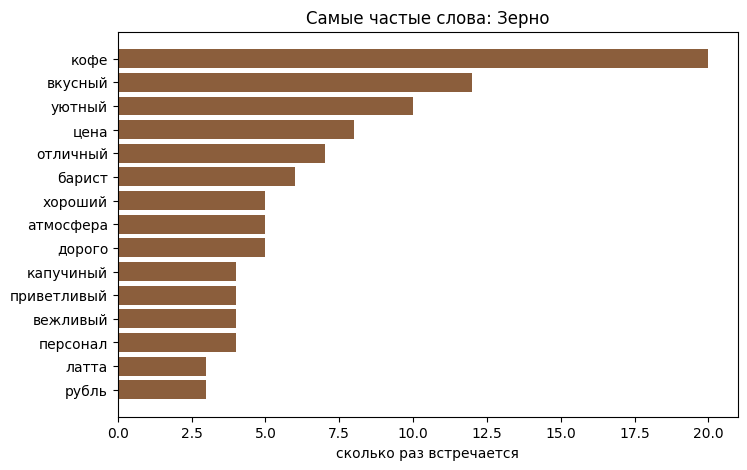

In [20]:
words = [w for w, c in top]
counts = [c for w, c in top]

plt.figure(figsize=(8, 5))
plt.barh(words[::-1], counts[::-1], color="#8B5E3C")
plt.title(f"Самые частые слова: {кофейня}")
plt.xlabel("сколько раз встречается")
plt.show()

## Шаг 7. На что жалуются?

Возьмём только плохие отзывы (1–2 звезды) о «Кофеине» и посмотрим, какие слова в них самые частые.

In [22]:
bad = df[(df["кофейня"] == "Кофеин") & (df["оценка"] <= 2)]

counter_bad = Counter()
for lemmas in bad["леммы"]:
    counter_bad.update(lemmas)

print("Плохих отзывов:", len(bad))
counter_bad.most_common(15)

Плохих отзывов: 4


[('цена', 3),
 ('поднять', 2),
 ('рубль', 2),
 ('деньга', 1),
 ('ожидать', 1),
 ('больший', 1),
 ('дорого', 1),
 ('капучиный', 1),
 ('перебор', 1),
 ('неадекватный', 1),
 ('латта', 1),
 ('третий', 1),
 ('год', 1)]

## Шаг 8. Чем кофейни отличаются: ключевые слова

Частые слова у обеих кофеен похожи — *кофе* есть везде. Полезнее найти слова, **характерные** именно для каждой кофейни.

Для каждого слова считаем его **долю** среди всех слов «Зерна» и среди всех слов «Кофеина» и смотрим, во сколько раз одна доля больше другой. Редкие слова (меньше 4 употреблений) не учитываем: на них сравнение ненадёжно.

In [23]:
zerno = Counter()
for lemmas in df[df["кофейня"] == "Зерно"]["леммы"]:
    zerno.update(lemmas)

kofein = Counter()
for lemmas in df[df["кофейня"] == "Кофеин"]["леммы"]:
    kofein.update(lemmas)

table = pd.DataFrame({"Зерно": zerno, "Кофеин": kofein}).fillna(0)
table = table[table.sum(axis=1) >= 4]                       # убираем редкие слова

# доля слова среди всех слов кофейни (+1, чтобы не делить на ноль)
table["доля_Зерно"]  = (table["Зерно"] + 1)  / table["Зерно"].sum()
table["доля_Кофеин"] = (table["Кофеин"] + 1) / table["Кофеин"].sum()
table["во_сколько_раз"] = table["доля_Зерно"] / table["доля_Кофеин"]

table = table.sort_values("во_сколько_раз", ascending=False)
print("Характерно для «Зерна»:")
print(table.head(10)[["Зерно", "Кофеин"]])
print("\nХарактерно для «Кофеина»:")
print(table.tail(10)[["Зерно", "Кофеин"]])

Характерно для «Зерна»:
             Зерно  Кофеин
уютный        10.0     0.0
отличный       7.0     0.0
вкусный       12.0     1.0
атмосфера      5.0     0.0
дорого         5.0     0.0
приветливый    4.0     0.0
вежливый       4.0     0.0
барист         6.0     1.0
капучиный      4.0     1.0
латта          3.0     1.0

Характерно для «Кофеина»:
            Зерно  Кофеин
новый         1.0     3.0
очередь       2.0     8.0
работать      1.0     6.0
заказ         1.0     7.0
комбо         0.0     4.0
минута        0.0     4.0
балл          0.0     4.0
недорого      0.0     5.0
ждать         0.0     6.0
приложение    0.0    20.0


## Шаг 9. Слово в контексте

Частота говорит, **сколько**, но не говорит, **как**. Найдём все отзывы, где встречается слово в любой форме: *цена, цены, цене*.

✍️ Как пишут о ценах в отзывах о «Зерне» и о «Кофеине»? Попробуйте другие слова: `"очередь"`, `"бариста"`, `"приложение"`.

In [24]:
слово = "цена"        # ← впишите любое слово

lemma = morph.parse(слово)[0].normal_form                     # лемма искомого слова
found = df[df["леммы"].apply(lambda lemmas: lemma in lemmas)]  # отзывы, где она есть

print(f"Отзывов со словом «{lemma}»: {len(found)}\n")
for _, row in found.head(15).iterrows():
    print(f"{row['кофейня']:6} {'★' * row['оценка']:5}  {row['текст']}")

Отзывов со словом «цена»: 15

Зерно  ★★★★   Кофе отличный, но цены кусаются: латте за 390 рублей.
Зерно  ★★     Опять подняли цены. За такие деньги ожидаешь большего.
Зерно  ★★★★   Вкусный кофе и вежливый персонал, но цены высокие.
Зерно  ★★★★   Кофе отличный. Жаль, что цены растут.
Зерно  ★★★    Кофе вкусный, но цены завышены, а порции маленькие.
Зерно  ★★     Цены неадекватные, латте почти 400 рублей.
Зерно  ★★★★   Кофе отличный, персонал вежливый. Цены, правда, высокие.
Зерно  ★★     Опять подняли цены, уже третий раз за год.
Кофеин ★★★★   Цены приятные, капучино дешевле, чем у конкурентов.
Кофеин ★★★★   Хорошее соотношение цены и качества. Удобно взять кофе с собой.
Кофеин ★★★    Цены радуют, но в зале тесно и шумно.
Кофеин ★★★★   Цены по-прежнему приятные, кофе нормальный.
Кофеин ★★★    Кофе нормальный, цены хорошие, но с приложением беда.
Кофеин ★★★★   Цены приятные, выгодные комбо.
Кофеин ★★★    Кофе обычный, цены хорошие.


## Шаг 10. Динамика: что менялось в течение года?

Посчитаем, сколько отзывов приходило каждой кофейне по месяцам.

In [25]:
by_month = pd.crosstab(df["дата"].dt.month, df["кофейня"])   # таблица: месяц × кофейня
by_month

кофейня,Зерно,Кофеин
дата,,
1,3,2
2,3,2
3,3,2
4,3,2
5,3,2
6,3,2
7,3,2
8,3,2
9,3,8


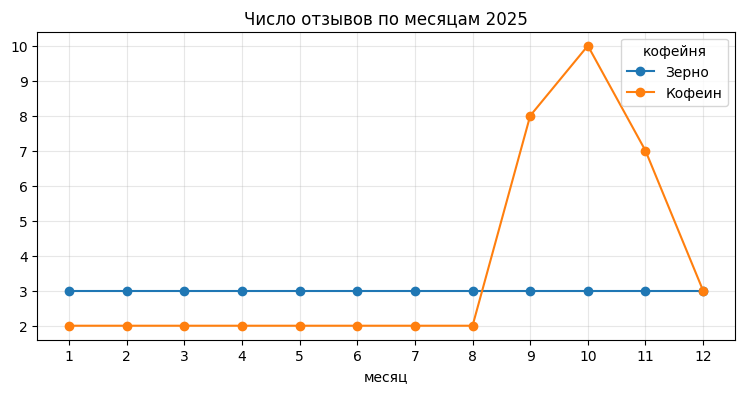

In [26]:
by_month.plot(marker="o", figsize=(9, 4))
plt.title("Число отзывов по месяцам 2025")
plt.xlabel("месяц")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.show()

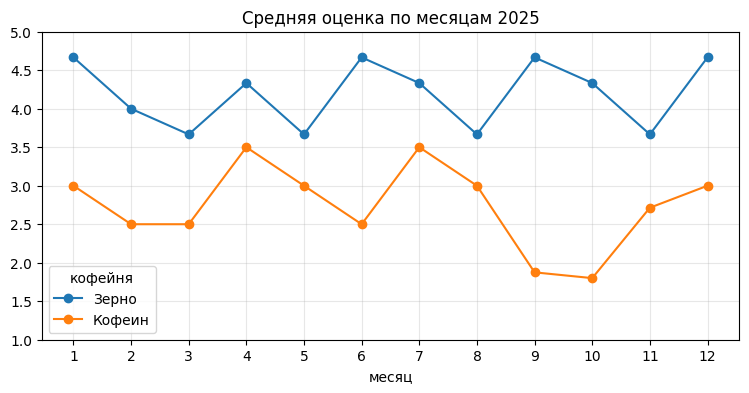

In [27]:
rating = df.pivot_table(index=df["дата"].dt.month, columns="кофейня",
                        values="оценка", aggfunc="mean")

rating.plot(marker="o", figsize=(9, 4))
plt.title("Средняя оценка по месяцам 2025")
plt.xlabel("месяц")
plt.xticks(range(1, 13))
plt.ylim(1, 5)
plt.grid(alpha=0.3)
plt.show()

## Шаг 11. Расследование: что случилось с «Кофеином» осенью?

С сентября по ноябрь отзывов о «Кофеине» стало в 3–5 раз больше, чем обычно. Какое слово могло бы это объяснить? Проверьте свою догадку: посмотрите, как часто оно встречается по месяцам.

✍️ Сформулируйте вывод в 2–3 предложениях: что произошло, когда, как реагировали клиенты, стало ли лучше к концу года.

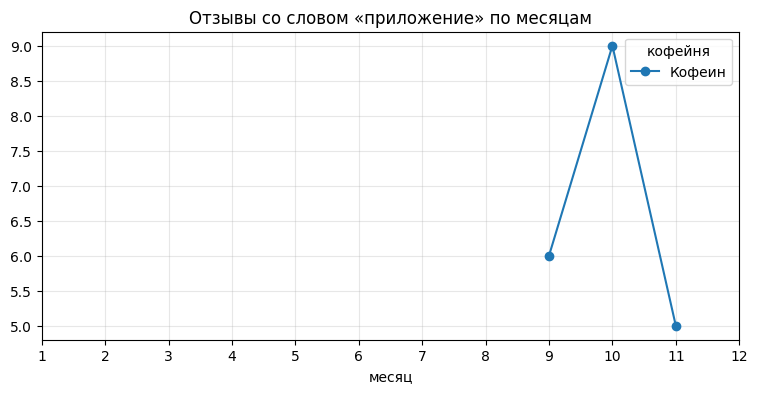

In [28]:
слово = "приложение"   # ← впишите любое слово

lemma = morph.parse(слово)[0].normal_form
found = df[df["леммы"].apply(lambda lemmas: lemma in lemmas)]

pd.crosstab(found["дата"].dt.month, found["кофейня"]).plot(marker="o", figsize=(9, 4))
plt.title(f"Отзывы со словом «{lemma}» по месяцам")
plt.xlabel("месяц")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.show()

## Шаг 12. Облако слов

Облако слов — самая известная визуализация текста: чем чаще слово, тем крупнее оно нарисовано. Построим облака для обеих кофеен рядом.

💬 Облако эффектно смотрится в презентации, но подумайте: насколько точно по нему можно сравнить, какое слово встречается чаще? Чем облако хуже столбчатой диаграммы из шага 6?

In [29]:
!pip install -q wordcloud

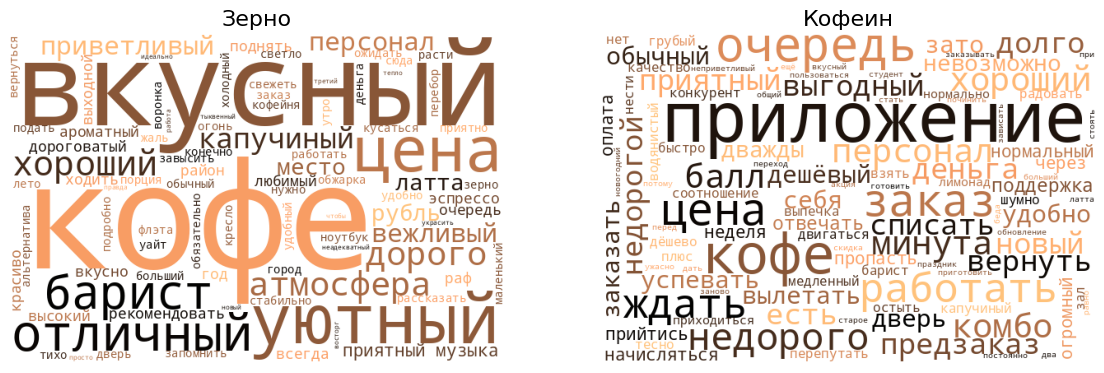

In [30]:
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 2, figsize=(14, 5))         # два графика рядом

for ax, кофейня in zip(axes, ["Зерно", "Кофеин"]):
    words = []
    for lemmas in df[df["кофейня"] == кофейня]["леммы"]:
        words.extend(lemmas)                             # собираем все леммы кофейни

    cloud = WordCloud(width=600, height=400, background_color="white",
                      colormap="copper", random_state=1).generate(" ".join(words))
    ax.imshow(cloud)
    ax.set_title(кофейня, fontsize=16)
    ax.axis("off")

plt.show()

## Шаг 13. Распределение оценок

Средняя оценка скрывает детали: средние 3 звезды могут получиться и из «все поставили 3», и из «половина поставила 1, половина — 5». Посмотрим, сколько отзывов с каждой оценкой.

In [31]:
stars = pd.crosstab(df["оценка"], df["кофейня"])
stars

кофейня,Зерно,Кофеин
оценка,,
1,0,11
2,4,13
3,4,9
4,9,11
5,19,0


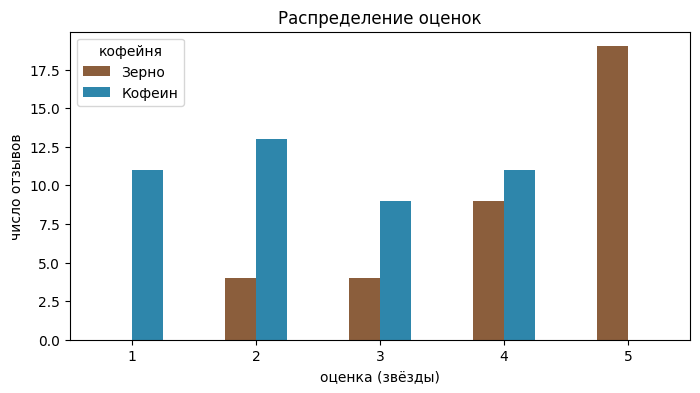

In [32]:
stars.plot(kind="bar", figsize=(8, 4), color=["#8B5E3C", "#2E86AB"])
plt.title("Распределение оценок")
plt.xlabel("оценка (звёзды)")
plt.ylabel("число отзывов")
plt.xticks(rotation=0)
plt.show()

## Шаг 14. Длина отзывов

Есть распространённая гипотеза: недовольные клиенты пишут длиннее, чем довольные. Проверим её на нашем корпусе: посчитаем среднее число слов в отзыве для каждой оценки.

In [33]:
df["длина"] = df["текст"].str.split().str.len()      # число слов в отзыве

df.groupby("оценка")["длина"].mean().round(1)

,длина
оценка,
1,6.9
2,7.1
3,6.7
4,6.0
5,7.3


💬 Подтвердилась ли гипотеза? Отрицательный результат — тоже результат: в нашем корпусе длина отзыва почти не зависит от оценки. На реальных данных стоит проверять такие «очевидные» гипотезы, а не принимать их на веру.

## Шаг 15. Как описывают кофейни: прилагательные

Прилагательные показывают, **какой** клиенты видят кофейню. Это готовый материал для позиционирования: словами клиентов можно говорить в рекламе.

`pymorphy3` определяет часть речи: `ADJF` — полное прилагательное (*уютный*), `ADJS` — краткое (*уютен*).

In [35]:
кофейня = "Зерно"     # ← поменяйте на "Кофеин"

adjectives = Counter()
for lemmas in df[df["кофейня"] == кофейня]["леммы"]:
    for lemma in lemmas:
        if morph.parse(lemma)[0].tag.POS in ("ADJF", "ADJS"):    # это прилагательное?
            adjectives[lemma] += 1

adjectives.most_common(10)

[('хороший', 4),
 ('выгодный', 3),
 ('приятный', 3),
 ('недорогой', 3),
 ('новый', 3),
 ('обычный', 2),
 ('дешёвый', 2),
 ('нормальный', 2),
 ('огромный', 2),
 ('медленный', 1)]

## Шаг 16. Биграммы: устойчивые сочетания слов

Отдельные слова теряют смысл: «приложение» — это хорошо или плохо? **Биграмма** — пара соседних слов. Сочетания вроде *«выгодный комбо»* или *«ждать заказ»* сразу показывают, о чём речь.

In [38]:
кофейня = "Кофеин"    # ← поменяйте на "Зерно"

bigrams = Counter()
for lemmas in df[df["кофейня"] == кофейня]["леммы"]:
    for i in range(len(lemmas) - 1):
        bigrams[lemmas[i] + " " + lemmas[i + 1]] += 1    # пара соседних слов

bigrams.most_common(10)

[('приложение работать', 5),
 ('недорого есть', 3),
 ('выгодный комбо', 3),
 ('ждать заказ', 3),
 ('цена приятный', 3),
 ('предзаказ приложение', 3),
 ('заказ минута', 2),
 ('минута персонал', 2),
 ('персонал успевать', 2),
 ('кофе обычный', 2)]

## Шаг 16а. Триграммы: сочетания из трёх слов

**Триграмма** — три соседних слова. Чем длиннее сочетание, тем конкретнее смысл: «приложение» → «предзаказ приложение» → «предзаказ в приложении не работает».

Посчитаем триграммы так же, как биграммы, — по леммам.

In [43]:
кофейня = "Кофеин"    # ← поменяйте на "Зерно"

trigrams = Counter()
for lemmas in df[df["кофейня"] == кофейня]["леммы"]:
    for i in range(len(lemmas) - 2):
        trigrams[" ".join(lemmas[i:i + 3])] += 1      # три соседних слова

trigrams.most_common(10)

[('предзаказ приложение работать', 3),
 ('ждать заказ минута', 2),
 ('заказ минута персонал', 2),
 ('минута персонал успевать', 2),
 ('приложение списать деньга', 2),
 ('списать деньга дважды', 2),
 ('недорого есть выгодный', 1),
 ('есть выгодный комбо', 1),
 ('выгодный комбо кофе', 1),
 ('комбо кофе плюс', 1)]

## Шаг 18. Извлечение фактов: цены и время ожидания

До сих пор мы считали слова. Но в отзывах есть и **конкретные факты**: сколько стоит латте, сколько клиент ждал заказ. Для PR это ценная информация: «клиенты жалуются на долгое ожидание» звучит слабее, чем «по отзывам, ждать заказ приходится в среднем 20 минут».

Достанем такие факты с помощью **регулярных выражений** — шаблонов для поиска в тексте. Регулярное выражение описывает, *как выглядит* то, что мы ищем.

| Элемент шаблона | Что означает | Пример |
|---|---|---|
| `\d` | любая цифра | `3`, `9` |
| `+` | «один или больше» того, что стоит перед ним | `\d+` → `390`, `20` |
| `\s*` | пробелы (ноль или больше) | `390 рублей`, `390рублей` |
| `руб` | просто буквы «руб» | найдёт *рублей*, *рубля*, *руб.* |
| `(...)` | «скобки»: эту часть нужно вернуть | `(\d+)` → вернуть только число |
| `(?:a\|b)` | «a или b» | `(?:руб\|₽)` → *рублей* или *₽* |

Шаблон `(\d+)\s*(?:руб|₽)` читается так: «число, после него, возможно, пробел, затем *руб* или *₽*. Верни число».

In [44]:
import re     # библиотека регулярных выражений (встроена в Python)

price_pattern = r"(\d+)\s*(?:руб|₽)"     # число + «руб» или «₽»
time_pattern  = r"(\d+)\s*мин"           # число + «мин» (минут, минуты, мин.)

# Проверим шаблоны на примерах
print(re.findall(price_pattern, "Цены кусаются: латте за 390 рублей, а капучино 350 руб."))
print(re.findall(time_pattern,  "Ждали заказ 20 минут, потом ещё 5 мин."))

['390', '350']
['20', '5']


Применим шаблоны ко всем отзывам. Найденные числа запишем в два новых столбца: `рубли` и `минуты`. Если в отзыве ничего не нашлось, там будет пустой список `[]`.

In [45]:
def find_numbers(text, pattern):
    "Находит в тексте все числа по шаблону и превращает их из строк в числа."
    return [int(x) for x in re.findall(pattern, text)]

df["рубли"]  = df["текст"].apply(lambda text: find_numbers(text, price_pattern))
df["минуты"] = df["текст"].apply(lambda text: find_numbers(text, time_pattern))

# Покажем только отзывы, где что-то нашлось
found = df[(df["рубли"].str.len() > 0) | (df["минуты"].str.len() > 0)]
found[["кофейня", "оценка", "текст", "рубли", "минуты"]]

,кофейня,оценка,текст,рубли,минуты
1,Зерно,4,"Кофе отличный, но цены кусаются: латте за 390 ...",[390],[]
12,Зерно,2,Слишком дорого. Капучино за 350 рублей — это п...,[350],[]
23,Зерно,2,"Цены неадекватные, латте почти 400 рублей.",[400],[]
37,Кофеин,2,Ждали заказ 20 минут. Персонал не успевает.,[],[20]
47,Кофеин,2,"Ждать приходится по 15 минут, очередь до двери.",[],[15]
62,Кофеин,2,Ждала заказ из приложения 30 минут.,[],[30]
74,Кофеин,2,"Ждали заказ 20 минут, персонал не успевает.",[],[20]


Теперь посчитаем итоги: сколько раз клиенты называли цену и время ожидания и какие значения в среднем.

`explode` «раскладывает» списки по отдельным строкам: если бы в одном отзыве было две цены, получилось бы две строки. `dropna` убирает строки, где ничего не нашлось.

In [46]:
prices = df.explode("рубли").dropna(subset=["рубли"])
prices["рубли"] = prices["рубли"].astype(int)

print("Цены, которые называют клиенты:")
print(prices.groupby("кофейня")["рубли"].agg(["count", "mean", "max"]))

waits = df.explode("минуты").dropna(subset=["минуты"])
waits["минуты"] = waits["минуты"].astype(int)

print("\nВремя ожидания, которое называют клиенты (минуты):")
print(waits.groupby("кофейня")["минуты"].agg(["count", "mean", "max"]))

Цены, которые называют клиенты:
         count   mean  max
кофейня                   
Зерно        3  380.0  400

Время ожидания, которое называют клиенты (минуты):
         count   mean  max
кофейня                   
Кофеин       4  21.25   30
